# N2 cold-gas vertical landing: design and descent simulator



| Block | Purpose |
|---|---|
| 1 | Imports |
| 2 | **Inputs** (CEA values, mission, vehicle, tank) |
| 3 | Helper functions (tank geometry and wall mass, real-gas tables) |
| 4 | Sizing: throat, mass flow, fill mass, tank mass, vehicle mass |
| 5 | Descent simulator (real-gas N2 via CoolProp) and ignition-height solver |
| 6 | Results and constraint check table |
| 7 | Trajectory plots |
| 8 | Touchdown speed vs ignition height |
| 9 | Constraint map in the fill pressure and tank volume plane |

Model: 1D vertical descent. No regulator, so chamber pressure equals tank pressure. Two thermal limits are run: **isothermal** (perfect heat transfer from the tank wall) and **adiabatic** (gas expands isentropically and cools). The real tank lies between them.

## Block 1: imports

In [4]:
!pip install coolprop    
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from CoolProp.CoolProp import PropsSI

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
g0 = 9.81          # m/s^2
FLUID = 'Nitrogen'
R_N2 = 8.314462618 / 0.0280134   # J/(kg K)
CHOKE = 1.893         # critical pressure ratio for gamma = 1.4 (choked if Pc > CHOKE * P_amb)

## Block 2: inputs (edit these)

In [5]:
# For Pc=6 bar 
Cstar_0     = 434.4     
Cf          = 1.1831       # -     thrust coefficient at your Pc/Pe or Ae/At
Isp_cea     = 52.385       # s     (Isp = Cf*C*/g0)
scale_cstar_with_T = True  # C* scales with sqrt(T) as the gas cools

# ===== B. Gas and tank state =====
T0          = 300.0      
P_amb       = 101325.0   
P_fill_bar  = 80.0      # bar   fill pressure =initial chamber pressure (no regulator)
V_tank_L    = .5        # L     internal tank volume
rho_n2_user = None       # kg/m3 optional: your N2 density at fill; CoolProp value is used for the model,
                         #       yours is only compared against it

# ===== C. Thrust requirement =====
F_target    = 60.0       # N     thrust at start of burn (sizes the throat)
F_min       = 28.0       # N     thrust must not fall below this

# ===== D. Mission =====
H               = 25.0   # m     drop height
v_touch_target  = 0.5    # m/s   allowed touchdown speed
t_valve         = 0.02   # s     valve opening time (thrust ramps linearly)
Cd, A_ref, rho_air = 0.0, 0.01, 1.225   # drag: set Cd > 0 to include (Cd, m^2, kg/m3)

# ===== E. Vehicle =====
m_dry       = 0.30       # kg    structure, valve, electronics, battery (everything except tank and gas)
TW_min      = 1.5       # -     required thrust/weight margin at all times during the burn

# ===== F. Tank wall (thin-wall cylinder with hemispherical caps) =====
tank_D_inner_mm = 25.4   # mm
rho_tank        = 7850.0 # kg/m3  p Steel 7850, Al 6061-T6 2700
sigma_yield_Pa  = 350e6  # Pa     Steel ~350e6, Al 6061-T6 ~275e6
safety_factor   = 2.5
t_min_mm        = 1.5    # mm     minimum manufacturable wall
P_rating_bar    = 250.0  # bar    highest pressure your tank, fittings and fill system allow

# ===== G. Constraint map settings =====
map_P_range_bar = (50.0, 300.0)
map_V_range_L   = (0.1, 3.0)
map_mode        = 'adiabatic'   # 'adiabatic' is the conservative thermal limit
prop_margin     = 1.2           # margin on required propellant

## Block 3: helper functions

In [6]:
def tank_wall_mass(P, V, D_i, rho_t, sigma_y, SF, t_min):
    # Thin-wall cylinder with hemispherical caps. Returns (mass kg, cylinder wall m, length m).
    r = D_i / 2
    L = (V - 4/3*np.pi*r**3) / (np.pi*r**2)
    if L < 0:
        return np.nan, np.nan, L
    s_allow = sigma_y / SF
    t_c = max(P*r/s_allow, t_min)
    t_s = max(P*r/(2*s_allow), t_min)
    m = rho_t * (2*np.pi*r*L*t_c + 4*np.pi*r**2*t_s)
    return m, t_c, L


def build_tank_table(mode, P0, T0, V, m0, n=200, frac_min=0.15):
    # Real-gas tank state as a function of remaining gas mass.
    # isothermal: T = T0.  adiabatic: remaining gas expands isentropically (constant entropy).
    s0 = PropsSI('S', 'P', P0, 'T', T0, FLUID)
    m_grid = np.linspace(frac_min*m0, m0, n)
    P = np.empty(n); T = np.empty(n)
    for i, m in enumerate(m_grid):
        rho = m / V
        if mode == 'isothermal':
            T[i] = T0
            P[i] = PropsSI('P', 'Dmass', rho, 'T', T0, FLUID)
        else:
            P[i] = PropsSI('P', 'Dmass', rho, 'S', s0, FLUID)
            T[i] = PropsSI('T', 'Dmass', rho, 'S', s0, FLUID)
    return m_grid, P, T

## Block 4: sizing

In [7]:
P0 = P_fill_bar * 1e5
V  = V_tank_L * 1e-3

rho0 = PropsSI('Dmass', 'P', P0, 'T', T0, FLUID)
if rho_n2_user is not None:
    print(f'Density check: yours {rho_n2_user:.1f} kg/m3 vs CoolProp {rho0:.1f} kg/m3 '
          f'({100*(rho_n2_user/rho0-1):+.1f} %). CoolProp value is used.')
m_gas0 = rho0 * V
Z0 = P0 / (rho0 * R_N2 * T0)

m_tank, t_wall, L_tank = tank_wall_mass(P0, V, tank_D_inner_mm/1e3, rho_tank,
                                        sigma_yield_Pa, safety_factor, t_min_mm/1e3)
if np.isnan(m_tank):
    raise ValueError('Tank volume is smaller than the two hemispherical caps. Increase V or reduce diameter.')
m_inert = m_dry + m_tank
M0 = m_inert + m_gas0

At       = F_target / (Cf * P0)
d_throat = np.sqrt(4*At/np.pi)
mdot0    = P0 * At / Cstar_0
Isp_calc = Cf * Cstar_0 / g0
M_max    = F_min / (TW_min * g0)

sizing = pd.Series({
    'N2 density at fill (kg/m3)': rho0,
    'Compressibility Z at fill': Z0,
    'N2 mass at fill (kg)': m_gas0,
    'Tank wall thickness, cylinder (mm)': t_wall*1e3,
    'Tank length, cylinder part (mm)': L_tank*1e3,
    'Tank mass (kg)': m_tank,
    'Vehicle mass at start (kg)': M0,
    'Max vehicle mass for T/W_min at F_min (kg)': M_max,
    'Throat area (mm2)': At*1e6,
    'Throat diameter (mm)': d_throat*1e3,
    'Initial mass flow (g/s)': mdot0*1e3,
    'Isp from Cf*C*/g0 (s)': Isp_calc,
    'Isp from CEA input (s)': Isp_cea,
}).round(4)
display(sizing.to_frame('value'))
if abs(Isp_calc/Isp_cea - 1) > 0.05:
    print('WARNING: Cf*C*/g0 differs from your Isp by more than 5 %. Check the CEA values come from the same run.')
if M0 > M_max:
    print(f'WARNING: vehicle mass {M0:.2f} kg is above the {M_max:.2f} kg limit. End-of-burn thrust cannot give T/W_min.')

tables = {mode: build_tank_table(mode, P0, T0, V, m_gas0) for mode in ('isothermal', 'adiabatic')}

,value
N2 density at fill (kg/m3),89.8181
Compressibility Z at fill,1.0003
N2 mass at fill (kg),0.0449
"Tank wall thickness, cylinder (mm)",1.5000
"Tank length, cylinder part (mm)",969.8293
Tank mass (kg),0.9351
Vehicle mass at start (kg),1.2800
Max vehicle mass for T/W_min at F_min (kg),1.9028
Throat area (mm2),6.3393
Throat diameter (mm),2.8410


## Block 5: descent simulator and ignition-height solver

In [56]:
def forces(t_rel, v, mg, table, burning):
    m_grid, Ptab, Ttab = table
    P = np.interp(mg, m_grid, Ptab)
    T = np.interp(mg, m_grid, Ttab)
    F = 0.0; mdot = 0.0
    if burning and mg > m_grid[0] and P > CHOKE * P_amb:
        ramp = min(1.0, t_rel / t_valve) if t_valve > 0 else 1.0
        cs = Cstar_0 * np.sqrt(T / T0) if scale_cstar_with_T else Cstar_0
        F = ramp * Cf * P * At
        mdot = ramp * P * At / cs
    Mtot = m_inert + mg
    drag = -np.sign(v) * 0.5 * rho_air * Cd * A_ref * v * v
    a = (F + drag) / Mtot - g0
    return F, mdot, P, T, Mtot, a


def simulate(h_ign, mode, t_max=20.0):
    table = tables[mode]
    h_ign = float(np.clip(h_ign, 1e-6, H))

    # phase 1: free fall until altitude h_ign
    def f1(t, s):
        y, v, mg = s
        return [v, -g0 - np.sign(v)*0.5*rho_air*Cd*A_ref*v*v/(m_inert+mg), 0.0]
    ev_ign = lambda t, s: s[0] - h_ign
    ev_ign.terminal = True; ev_ign.direction = -1
    if h_ign >= H:
        t_ign, s_ign = 0.0, np.array([H, 0.0, m_gas0])
        T1, Y1 = np.array([0.0]), np.array([[H], [0.0], [m_gas0]])
    else:
        s1 = solve_ivp(f1, (0, t_max), [H, 0.0, m_gas0], events=ev_ign,
                       max_step=0.01, rtol=1e-8, atol=1e-10)
        t_ign, s_ign = s1.t_events[0][0], s1.y_events[0][0]
        T1, Y1 = s1.t, s1.y

    # phase 2: burn until touchdown or until the vehicle stops above ground
    def f2(t, s):
        y, v, mg = s
        F, mdot, P, T, Mtot, a = forces(t - t_ign, v, mg, table, True)
        return [v, a, -mdot]
    ev_gnd = lambda t, s: s[0]
    ev_gnd.terminal = True; ev_gnd.direction = -1
    ev_up = lambda t, s: s[1]
    ev_up.terminal = True; ev_up.direction = 1
    s2 = solve_ivp(f2, (t_ign, t_ign + t_max), s_ign, events=[ev_gnd, ev_up],
                   max_step=0.002, rtol=1e-7, atol=1e-9)

    t = np.concatenate([T1, s2.t]); Y = np.hstack([Y1, s2.y])
    y, v, mg = Y
    burning = t >= t_ign
    F = np.zeros_like(t); P = np.zeros_like(t); Tg = np.zeros_like(t); Mtot = np.zeros_like(t)
    for i in range(len(t)):
        F[i], _, P[i], Tg[i], Mtot[i], _ = forces(t[i]-t_ign, v[i], mg[i], table, burning[i])

    if s2.t_events[0].size:
        status, v_touch = 'touchdown', -v[-1]
    elif s2.t_events[1].size:
        status, v_touch = 'stopped above ground', 0.0
    else:
        status, v_touch = 'timeout', np.nan

    b = burning & (t - t_ign >= t_valve)
    if not b.any():
        b = burning
    tw = F[b] / (Mtot[b] * g0)
    below = np.where(F[b] < F_min)[0]
    return dict(t=t, y=y, v=v, mg=mg, F=F, P=P, T=Tg, Mtot=Mtot, t_ign=t_ign, h_ign=h_ign,
                status=status, v_touch=v_touch, burn_time=t[-1]-t_ign,
                prop_used=m_gas0 - mg[-1], F_start=F[b][0] if b.any() else 0.0, F_end=F[-1],
                TW_min_seen=tw.min() if tw.size else 0.0, P_end=P[-1], T_end=Tg[-1],
                P_min_burn=P[b].min() if b.any() else P[-1],
                t_below_Fmin=(t[b][below[0]] - t_ign) if below.size else None)


def solve_ignition(mode, target=None, iters=30):
    # Highest-altitude-free solution: the LATEST ignition height that still gives touchdown <= target.
    target = v_touch_target if target is None else target
    f = lambda h: simulate(h, mode)['v_touch'] - target
    lo, hi = 0.0, H
    if f(hi) > 0:
        return None
    for _ in range(iters):
        mid = 0.5*(lo+hi)
        if f(mid) > 0: lo = mid
        else: hi = mid
    return hi

## Block 6: results and constraint check

In [57]:
results = {}
for mode in ('isothermal', 'adiabatic'):
    h = solve_ignition(mode)
    if h is None:
        print(f'[{mode}] No ignition height can reach the touchdown target. Thrust or mass is the problem.')
        continue
    results[mode] = simulate(h, mode)

rows = {}
for mode, r in results.items():
    rows[mode] = {
        'Ignition height (m)': r['h_ign'],
        'Ignition speed (m/s)': -np.interp(r['t_ign'], r['t'], r['v']),
        'Burn time (s)': r['burn_time'],
        'Touchdown speed (m/s)': r['v_touch'],
        'End status': r['status'],
        'Thrust start (N)': r['F_start'],
        'Thrust at touchdown (N)': r['F_end'],
        'Min thrust/weight': r['TW_min_seen'],
        'N2 used (g)': r['prop_used']*1e3,
        'N2 left (g)': (m_gas0 - r['prop_used'])*1e3,
        'Tank P at end (bar)': r['P_end']/1e5,
        'Gas T at end (K)': r['T_end'],
    }
summary = pd.DataFrame(rows)
display(summary.map(lambda x: round(x, 3) if isinstance(x, (int, float, np.floating)) else x))

checks = []
for mode, r in results.items():
    checks += [
        (mode, f'Touchdown speed <= {v_touch_target} m/s', r['v_touch'] <= v_touch_target + 1e-3, f"{r['v_touch']:.2f} m/s"),
        (mode, f'Thrust >= {F_min} N during burn', r['F_end'] >= F_min, f"{r['F_end']:.2f} N at end"),
        (mode, f'Thrust/weight >= {TW_min}', r['TW_min_seen'] >= TW_min, f"min {r['TW_min_seen']:.2f}"),
        (mode, 'Nozzle choked (Pc > 1.89 Pamb)', r['P_min_burn'] > CHOKE*P_amb, f"min Pc {r['P_min_burn']/1e5:.1f} bar"),
        (mode, 'Fill pressure within rating', P_fill_bar <= P_rating_bar, f'{P_fill_bar:.0f} <= {P_rating_bar:.0f} bar'),
        (mode, 'Vehicle mass within T/W limit', M0 <= M_max, f'{M0:.2f} <= {M_max:.2f} kg'),
    ]
chk = pd.DataFrame(checks, columns=['case', 'constraint', 'pass', 'value'])
chk['pass'] = chk['pass'].map({True: 'PASS', False: 'FAIL'})
display(chk.pivot(index='constraint', columns='case', values=['pass', 'value']))

,isothermal,adiabatic
Ignition height (m),14.42,20.471
Ignition speed (m/s),14.407,9.427
Burn time (s),1.322,0.959
Touchdown speed (m/s),0.0,0.0
End status,stopped above ground,stopped above ground
Thrust start (N),59.244,58.75
Thrust at touchdown (N),14.258,14.446
Min thrust/weight,1.0,1.0
N2 used (g),79.487,60.409
N2 left (g),26.782,45.86


pass                       value  \
case                           adiabatic isothermal        adiabatic   
constraint                                                             
Fill pressure within rating         PASS       PASS   200 <= 250 bar   
Nozzle choked (Pc > 1.89 Pamb)      PASS       PASS  min Pc 48.2 bar   
Thrust >= 28.0 N during burn        FAIL       FAIL   14.45 N at end   
Thrust/weight >= 1.5                FAIL       FAIL         min 1.00   
Touchdown speed <= 0.5 m/s          PASS       PASS         0.00 m/s   
Vehicle mass within T/W limit       PASS       PASS  1.53 <= 1.90 kg   

                                                 
case                                 isothermal  
constraint                                       
Fill pressure within rating      200 <= 250 bar  
Nozzle choked (Pc > 1.89 Pamb)  min Pc 47.5 bar  
Thrust >= 28.0 N during burn     14.26 N at end  
Thrust/weight >= 1.5                   min 1.00  
Touchdown speed <= 0.5 m/s             0.00 m/s  
Vehicle mass within T/W limit   1.53 <= 1.90 kg

## Block 7: trajectory plots with constraint lines

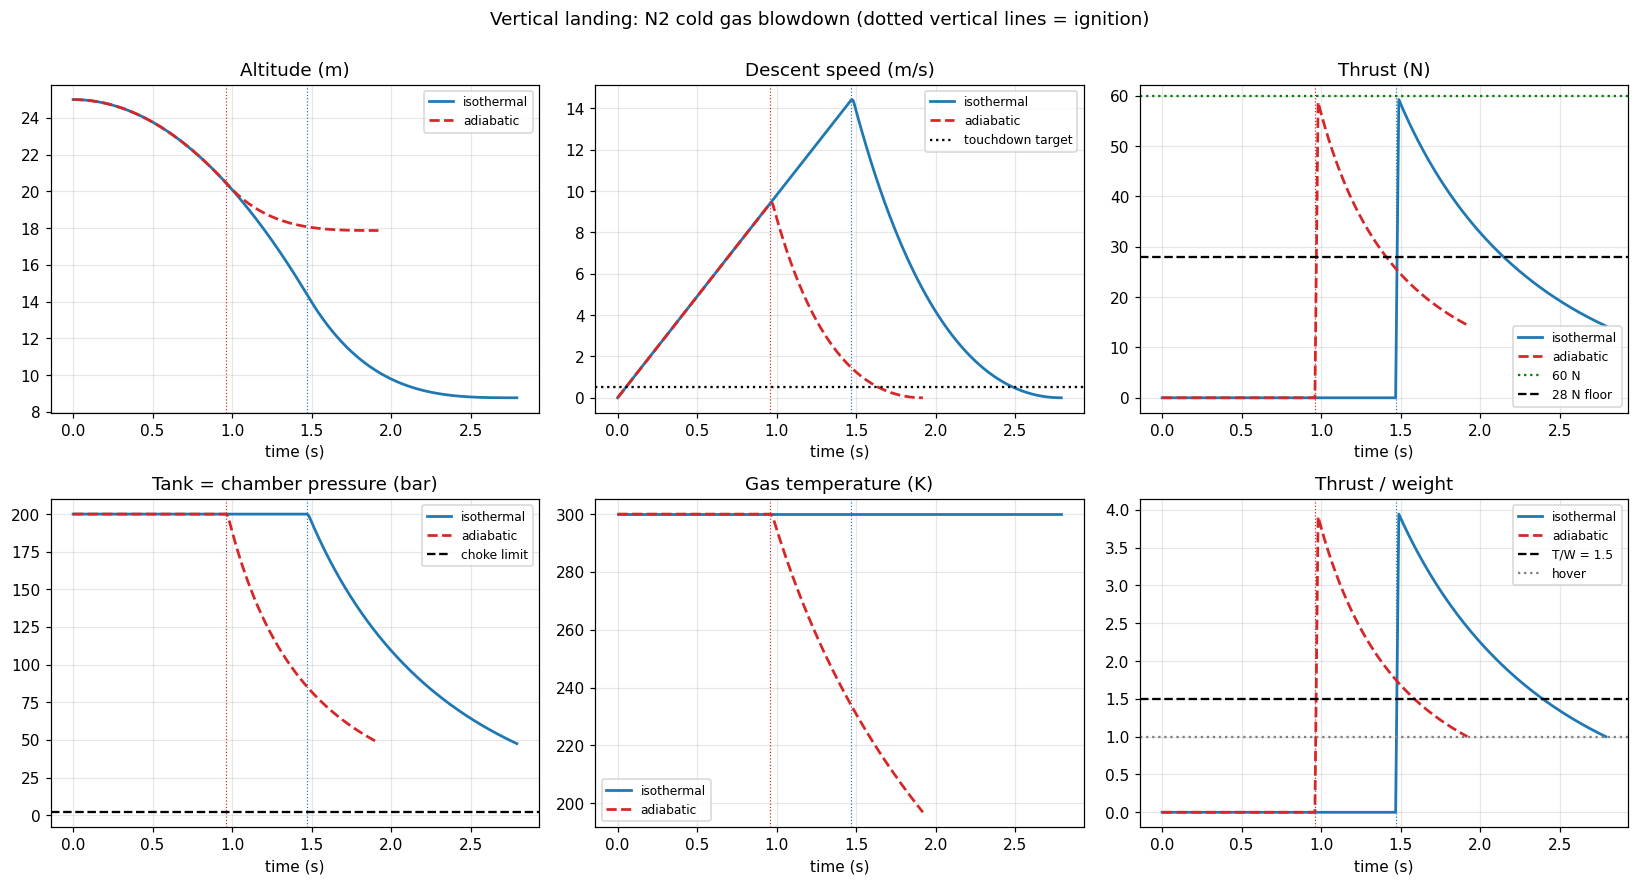

In [58]:
style = {'isothermal': dict(ls='-', lw=1.8, color='tab:blue'),
         'adiabatic':  dict(ls='--', lw=1.8, color='tab:red')}
fig, ax = plt.subplots(2, 3, figsize=(15, 8))
ax = ax.ravel()
for mode, r in results.items():
    t = r['t']; s = style[mode]
    ax[0].plot(t, r['y'], label=mode, **s)
    ax[1].plot(t, -r['v'], label=mode, **s)
    ax[2].plot(t, r['F'], label=mode, **s)
    ax[3].plot(t, r['P']/1e5, label=mode, **s)
    ax[4].plot(t, r['T'], label=mode, **s)
    with np.errstate(divide='ignore', invalid='ignore'):
        ax[5].plot(t, r['F']/(r['Mtot']*g0), label=mode, **s)
    for a in ax: a.axvline(r['t_ign'], color=s['color'], ls=':', lw=0.8)
ax[1].axhline(v_touch_target, color='k', ls=':', label='touchdown target')
ax[2].axhline(F_target, color='g', ls=':', label=f'{F_target:.0f} N'); ax[2].axhline(F_min, color='k', ls='--', label=f'{F_min:.0f} N floor')
ax[3].axhline(CHOKE*P_amb/1e5, color='k', ls='--', label='choke limit')
ax[5].axhline(TW_min, color='k', ls='--', label=f'T/W = {TW_min}'); ax[5].axhline(1.0, color='gray', ls=':', label='hover')
titles = ['Altitude (m)', 'Descent speed (m/s)', 'Thrust (N)', 'Tank = chamber pressure (bar)', 'Gas temperature (K)', 'Thrust / weight']
for a, tt in zip(ax, titles):
    a.set_title(tt); a.set_xlabel('time (s)'); a.legend(fontsize=8)
fig.suptitle('Vertical landing: N2 cold gas blowdown (dotted vertical lines = ignition)', y=1.0)
plt.tight_layout(); plt.show()

## Block 8: touchdown speed vs ignition height (the timing window)

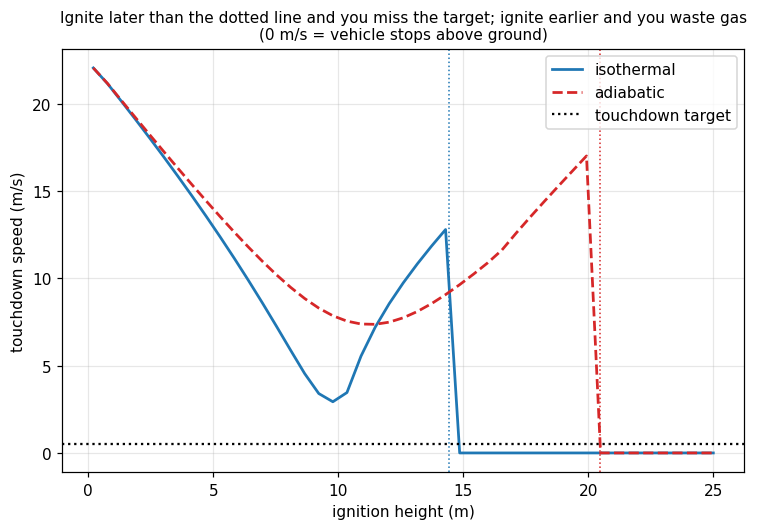

In [59]:
h_sweep = np.linspace(0.2, H, 45)
plt.figure(figsize=(8, 5))
for mode in ('isothermal', 'adiabatic'):
    vt = [simulate(h, mode)['v_touch'] for h in h_sweep]
    plt.plot(h_sweep, vt, label=mode, **style[mode])
    if mode in results:
        plt.axvline(results[mode]['h_ign'], color=style[mode]['color'], ls=':', lw=1)
plt.axhline(v_touch_target, color='k', ls=':', label='touchdown target')
plt.xlabel('ignition height (m)'); plt.ylabel('touchdown speed (m/s)')
plt.title('Ignite later than the dotted line and you miss the target; ignite earlier and you waste gas\n'
          '(0 m/s = vehicle stops above ground)', fontsize=10)
plt.legend(); plt.show()

## Block 9: constraint map in the (fill pressure, tank volume) plane

Fast screening, not a full simulation. For each design point it computes the gas usable above the thrust floor
(real gas, thermal limit `map_mode`), compares it with the propellant needed (constant mean thrust, hand-calculation estimate, times `prop_margin`),
and checks thrust/weight at start and at the floor. Use Blocks 5 to 8 to confirm the design you pick.

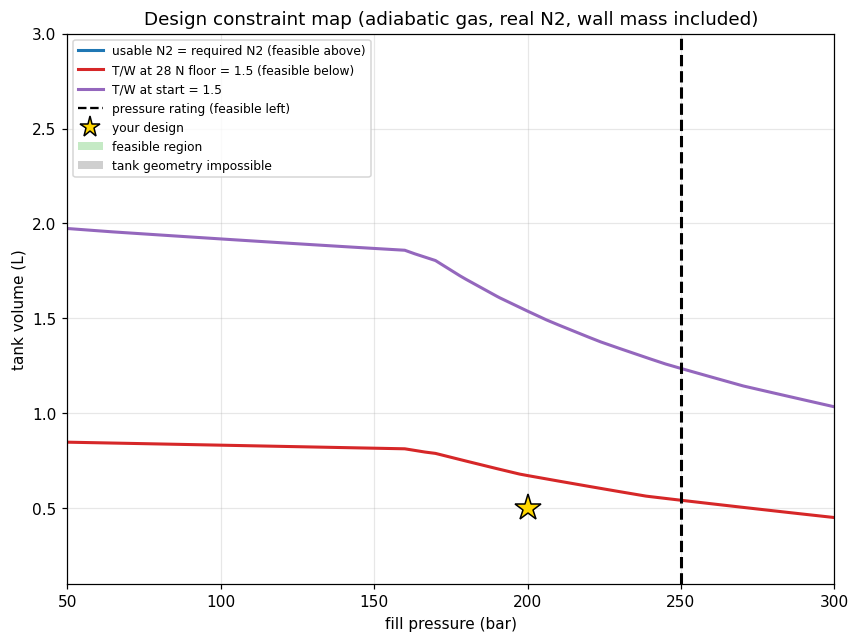

Your design (200 bar, 0.50 L): usable N2 37 g, required (with margin) 98 g, T/W start 3.99, T/W at floor 1.91


In [61]:
def screen_design(P_bar, V_L, mode):
    P_ = P_bar*1e5; V_ = V_L*1e-3
    rho0_ = PropsSI('Dmass', 'P', P_, 'T', T0, FLUID)
    P_fl = P_ * F_min / F_target
    if mode == 'isothermal':
        rho_f = PropsSI('Dmass', 'P', P_fl, 'T', T0, FLUID)
    else:
        s0_ = PropsSI('S', 'P', P_, 'T', T0, FLUID)
        rho_f = PropsSI('Dmass', 'P', P_fl, 'S', s0_, FLUID)
    m0_, mf_ = rho0_*V_, rho_f*V_
    mt, _, _ = tank_wall_mass(P_, V_, tank_D_inner_mm/1e3, rho_tank, sigma_yield_Pa, safety_factor, t_min_mm/1e3)
    if np.isnan(mt):
        return dict(usable=np.nan, need=np.nan, ratio=np.nan, TW0=np.nan, TWf=np.nan, M0=np.nan)
    M0_ = m_dry + mt + m0_;  Mf_ = m_dry + mt + mf_
    F_avg = 0.5*(F_target + F_min)
    if F_avg <= M0_*g0:
        need = np.inf
    else:
        h_i = H * M0_*g0 / F_avg
        
        v_i = np.sqrt(2*g0*max(H - h_i, 0.0))
        t_b = v_i / (F_avg/M0_ - g0)
        need = prop_margin * (F_avg/(Cf*Cstar_0)) * t_b
    usable = m0_ - mf_
    return dict(usable=usable, need=need, ratio=usable/need if need > 0 else np.inf,
                TW0=F_target/(M0_*g0), TWf=F_min/(Mf_*g0), M0=M0_)

Ps = np.linspace(*map_P_range_bar, 26)
Vs = np.linspace(*map_V_range_L, 26)
G = {k: np.full((len(Vs), len(Ps)), np.nan) for k in ('ratio', 'TW0', 'TWf', 'M0', 'usable', 'need')}
for i, Vl in enumerate(Vs):
    for j, Pb in enumerate(Ps):
        d = screen_design(Pb, Vl, map_mode)
        for k in G: G[k][i, j] = d[k]

PP, VV = np.meshgrid(Ps, Vs)
valid = ~np.isnan(G['ratio'])
feasible = valid & (G['ratio'] >= 1) & (G['TW0'] >= TW_min) & (G['TWf'] >= TW_min) & (PP <= P_rating_bar)

fig, ax = plt.subplots(figsize=(9, 6.5))
ax.contourf(PP, VV, feasible.astype(float), levels=[0.5, 1.5], colors=['#9fdc9f'], alpha=0.6)
ax.contourf(PP, VV, (~valid).astype(float), levels=[0.5, 1.5], colors=['#bbbbbb'], alpha=0.7)
handles = []
def add(Z, level, color, label):
    Zm = np.ma.masked_invalid(np.where(np.isfinite(Z), Z, np.nan))
    if np.nanmin(Zm) < level < np.nanmax(Zm):
        ax.contour(PP, VV, Zm, levels=[level], colors=[color], linewidths=2)
    handles.append(plt.Line2D([], [], color=color, lw=2, label=label))
add(np.minimum(G['ratio'], 50), 1.0, 'tab:blue', 'usable N2 = required N2 (feasible above)')
add(G['TWf'], TW_min, 'tab:red', f'T/W at {F_min:.0f} N floor = {TW_min} (feasible below)')
add(G['TW0'], TW_min, 'tab:purple', f'T/W at start = {TW_min}')
ax.axvline(P_rating_bar, color='k', ls='--', lw=2); handles.append(plt.Line2D([], [], color='k', ls='--', label='pressure rating (feasible left)'))
ax.plot(P_fill_bar, V_tank_L, marker='*', ms=18, color='gold', mec='k', ls='')
handles += [plt.Line2D([], [], marker='*', color='gold', mec='k', ls='', ms=14, label='your design'),
            plt.Rectangle((0, 0), 1, 1, fc='#9fdc9f', alpha=0.6, label='feasible region'),
            plt.Rectangle((0, 0), 1, 1, fc='#bbbbbb', alpha=0.7, label='tank geometry impossible')]
ax.legend(handles=handles, fontsize=8, loc='upper left')
ax.set_xlabel('fill pressure (bar)'); ax.set_ylabel('tank volume (L)')
ax.set_title(f'Design constraint map ({map_mode} gas, real N2, wall mass included)')
plt.show()

here = screen_design(P_fill_bar, V_tank_L, map_mode)
print(f"Your design ({P_fill_bar:.0f} bar, {V_tank_L:.2f} L): usable N2 {here['usable']*1e3:.0f} g, "
      f"required (with margin) {here['need']*1e3:.0f} g, T/W start {here['TW0']:.2f}, T/W at floor {here['TWf']:.2f}")